In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
df = pd.read_csv('Titanic-Dataset.csv')
df

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S
...,...,...,...,...,...,...,...,...,...,...,...,...
886,887,0,2,"Montvila, Rev. Juozas",male,27.0,0,0,211536,13.0000,NaN,S
887,888,1,1,"Graham, Miss. Margaret Edith",female,19.0,0,0,112053,30.0000,B42,S
888,889,0,3,"Johnston, Miss. Catherine Helen ""Carrie""",female,NaN,1,2,W./C. 6607,23.4500,NaN,S
889,890,1,1,"Behr, Mr. Karl Howell",male,26.0,0,0,111369,30.0000,C148,C


In [2]:
df['Title'] = df['Name'].str.extract(r' ([A-Za-z]+)\.', expand=False)
df['Title'] = df['Title'].replace({'Mlle': 'Miss', 'Ms': 'Miss', 'Mme': 'Mrs'})
df['Title'] = df['Title'].where(df['Title'].isin(['Mr', 'Miss', 'Mrs', 'Master']), 'Rare')
df['FamilySize'] = df['SibSp'] + df['Parch'] + 1
df['IsAlone'] = (df['FamilySize'] == 1).astype(int)
df['HasCabin'] = df['Cabin'].notnull().astype(int)
df['Pclass'] = df['Pclass'].astype(str)
df.drop(['PassengerId', 'Name', 'Ticket', 'Cabin'], axis=1, inplace=True)
df

,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked,Title,FamilySize,IsAlone,HasCabin
0,0,3,male,22.0,1,0,7.2500,S,Mr,2,0,0
1,1,1,female,38.0,1,0,71.2833,C,Mrs,2,0,1
2,1,3,female,26.0,0,0,7.9250,S,Miss,1,1,0
3,1,1,female,35.0,1,0,53.1000,S,Mrs,2,0,1
4,0,3,male,35.0,0,0,8.0500,S,Mr,1,1,0
...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Rare,1,1,0
887,1,1,female,19.0,0,0,30.0000,S,Miss,1,1,1
888,0,3,female,NaN,1,2,23.4500,S,Miss,4,0,0
889,1,1,male,26.0,0,0,30.0000,C,Mr,1,1,1


In [3]:
X = df.drop('Survived', axis=1)
y = df['Survived']
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, shuffle=True, stratify=y)
y_train.value_counts()

Survived
0    439
1    273
Name: count, dtype: int64

In [4]:
from sklearn.impute import SimpleImputer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.linear_model import LogisticRegression
X_nums = X_train.select_dtypes(include=np.number).columns
X_cat = X_train.select_dtypes(exclude=np.number).columns
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])
cat_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy='constant', fill_value='Missing')),
    ('one-hot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])
transformer = ColumnTransformer([
    ('num', num_pipeline, X_nums),
    ('cat', cat_pipeline, X_cat)
])
full_pipeline = Pipeline([
    ('preprocessing', transformer),
    ('estimator', LogisticRegression(max_iter=1000))
])

In [5]:
from sklearn.model_selection import GridSearchCV
grid = GridSearchCV(
    full_pipeline,
    {'estimator__C': [0.01, 0.1, 1, 10, 100], 'estimator__class_weight': [None, 'balanced']},
    cv=5,
    scoring='roc_auc',
    n_jobs=-1
)
grid.fit(X_train, y_train)
best_model = grid.best_estimator_
grid.best_params_, grid.best_score_

({'estimator__C': 1, 'estimator__class_weight': None},
 np.float64(0.8684099089114763))

In [6]:
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import precision_recall_curve
train_scores = cross_val_predict(best_model, X_train, y_train, cv=5, method='decision_function')
precisions, recalls, thresholds = precision_recall_curve(y_train, train_scores)
f1s = 2 * precisions[:-1] * recalls[:-1] / (precisions[:-1] + recalls[:-1] + 1e-12)
threshold = thresholds[f1s.argmax()]
threshold

np.float64(-0.0076162860105474794)

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score, confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay
test_scores = best_model.decision_function(X_test)
y_pred = (test_scores > threshold).astype(int)
metrics = {
    'accuracy': accuracy_score(y_test, y_pred),
    'precision': precision_score(y_test, y_pred),
    'recall': recall_score(y_test, y_pred),
    'f1': f1_score(y_test, y_pred),
    'roc_auc': roc_auc_score(y_test, test_scores)
}
metrics

{'accuracy': 0.8324022346368715,
 'precision': 0.8,
 'recall': 0.7536231884057971,
 'f1': 0.7761194029850746,
 'roc_auc': 0.8722002635046112}

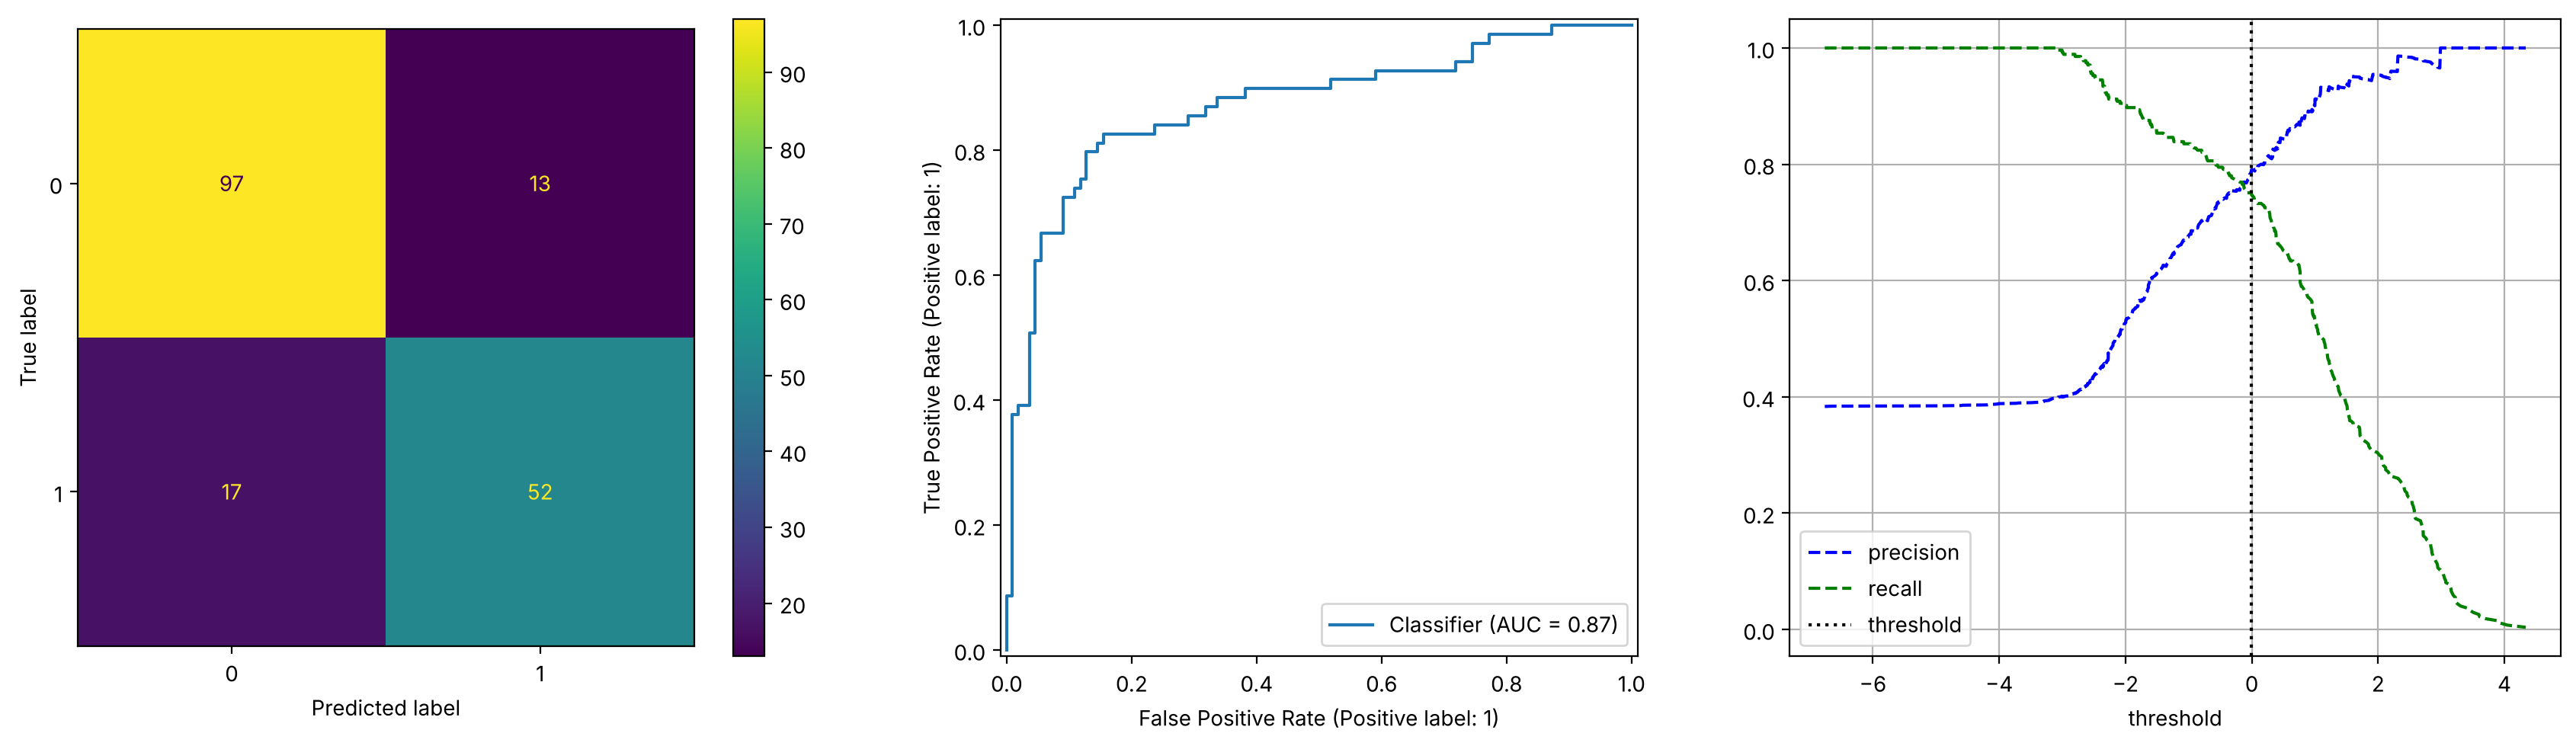

In [8]:
fig, axes = plt.subplots(1, 3, figsize=(17, 5))
ConfusionMatrixDisplay(confusion_matrix(y_test, y_pred)).plot(ax=axes[0])
RocCurveDisplay.from_predictions(y_test, test_scores, ax=axes[1])
axes[2].plot(thresholds, precisions[:-1], 'b--', label='precision')
axes[2].plot(thresholds, recalls[:-1], 'g--', label='recall')
axes[2].axvline(threshold, color='k', linestyle=':', label='threshold')
axes[2].set_xlabel('threshold')
axes[2].legend()
axes[2].grid(True)
plt.tight_layout()
plt.show()

In [9]:
print(' | '.join(f'{k}: {v:.2f}' for k, v in metrics.items()))

accuracy: 0.83 | precision: 0.80 | recall: 0.75 | f1: 0.78 | roc_auc: 0.87
